1. SOURCE DENSITY NORMALIZATION
Numerical integral of rho0 = 0.999995814964167
Exact source mass = 1
Absolute source mass error = 4.1850358329931225e-06
PASS: Source density is correctly normalized.

2. SOURCE CDF CHECK
F0 numerical minimum = 0.0
F0 numerical maximum = 1.0
Numerical F0 monotone = True
Maximum |F0 numerical - F0 exact| = 2.027378599793808e-06
PASS: Numerical source CDF is nondecreasing.

3. GAUSSIAN TARGET CHECK
Gaussian plot interval = (-6.0, 6.0)
Gaussian mass captured numerically on plotting interval = 0.9999999980268233
Gaussian mass outside plotting interval = 1.9731767331165884e-09
Gaussian CDF monotone on grid = True
Gaussian CDF at left grid boundary = 9.865876450376946e-10
Gaussian CDF at right grid boundary = 0.9999999990134123
PASS: Gaussian CDF is nondecreasing.
NOTE: The full Gaussian has exact total mass 1 on R.
The finite interval is not being treated as all of R.

4. FULL OPTIMAL TRANSPORT MAP
T(x) monotone = True
Maximum |Phi(T(x)) - F0(x)| = 2.22044604

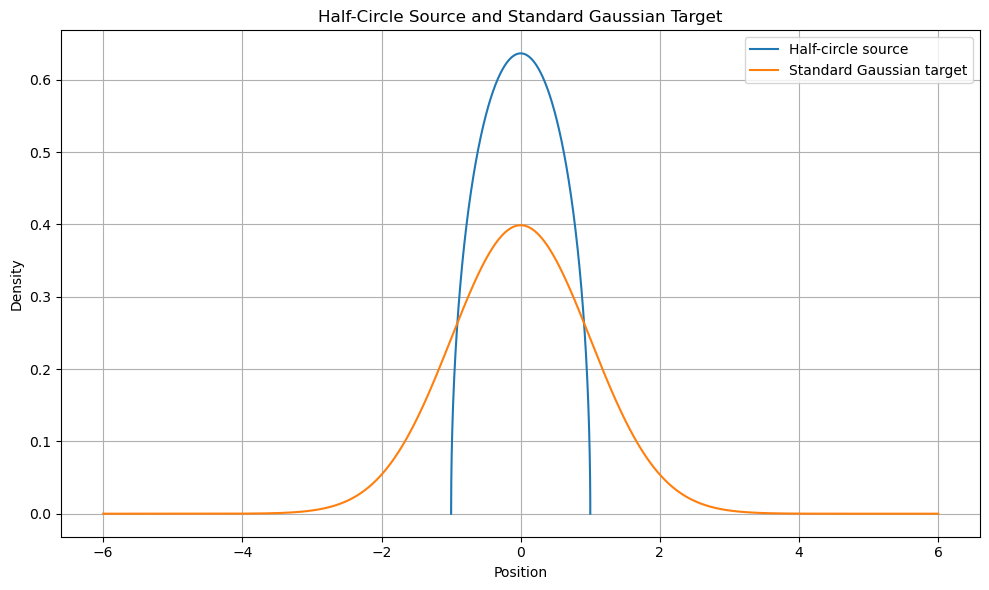

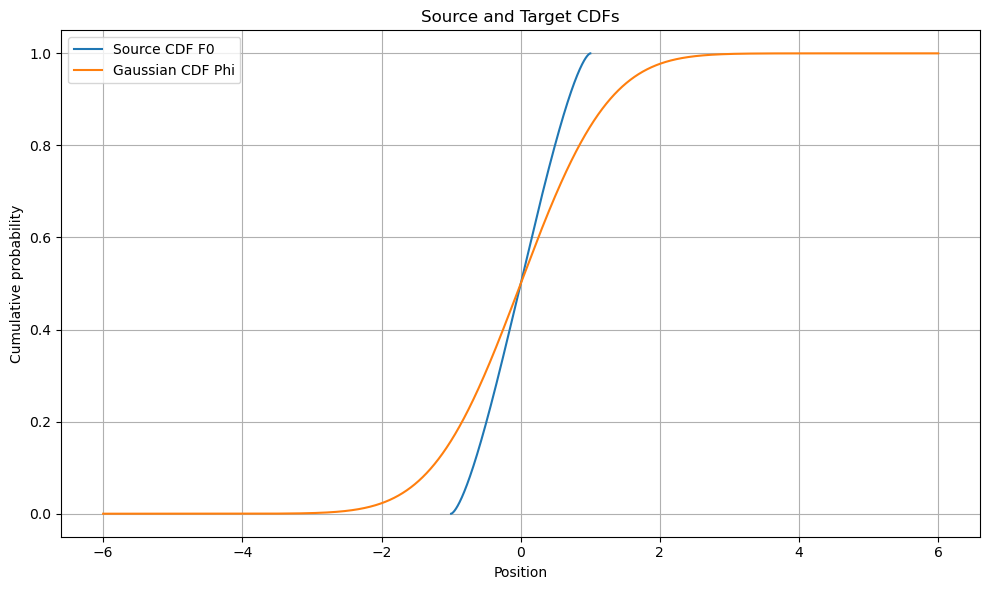

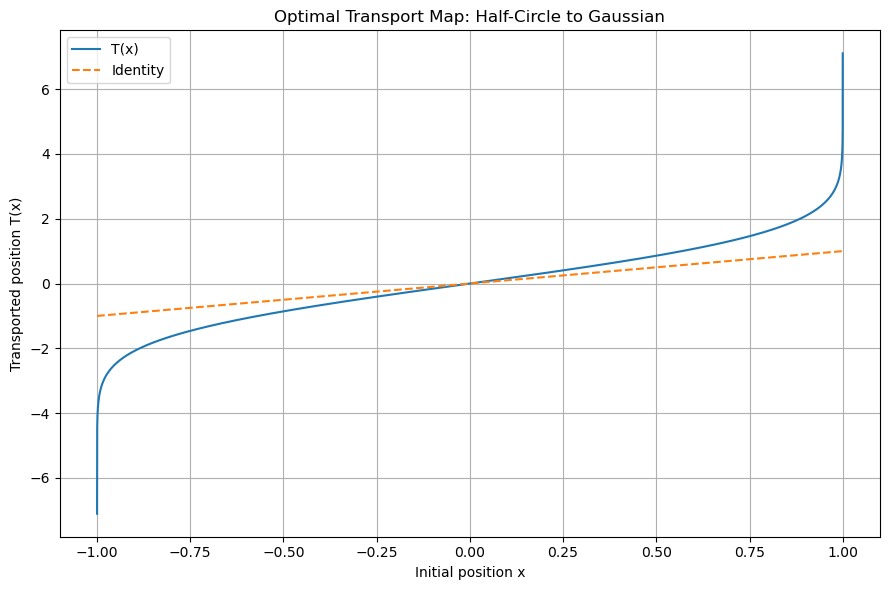

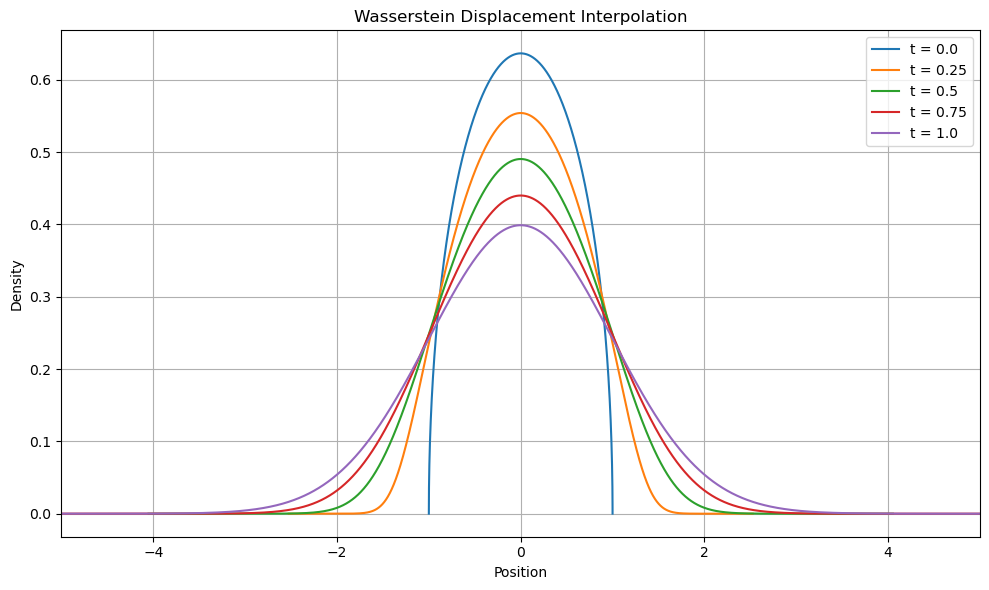

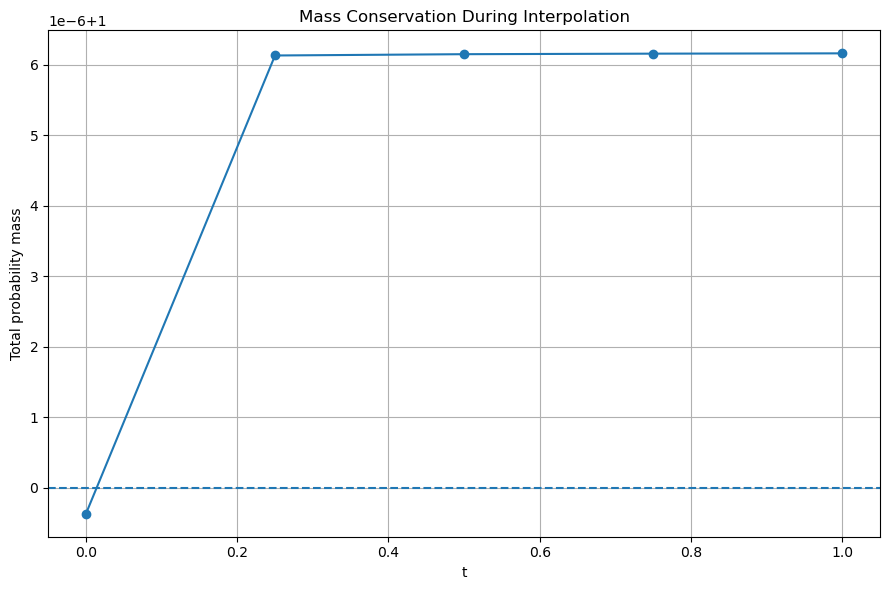

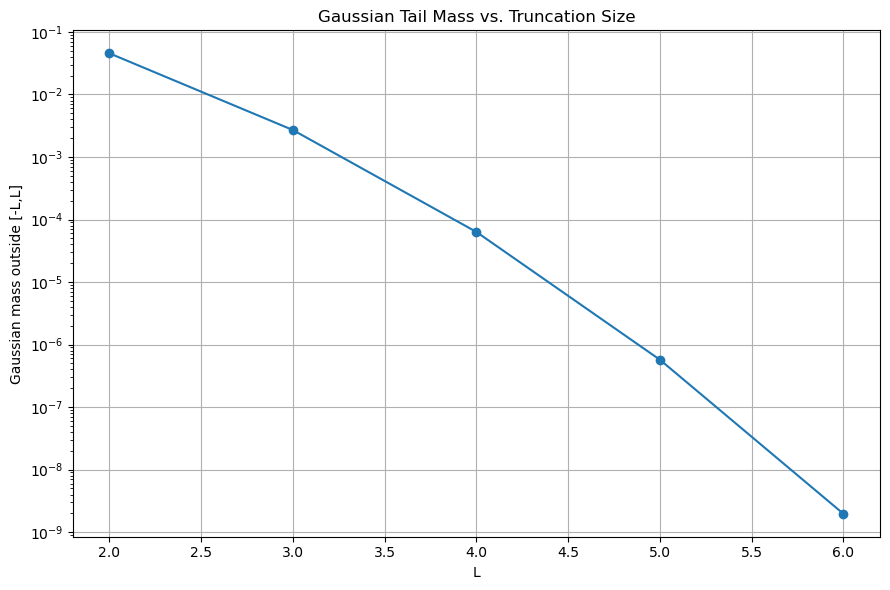

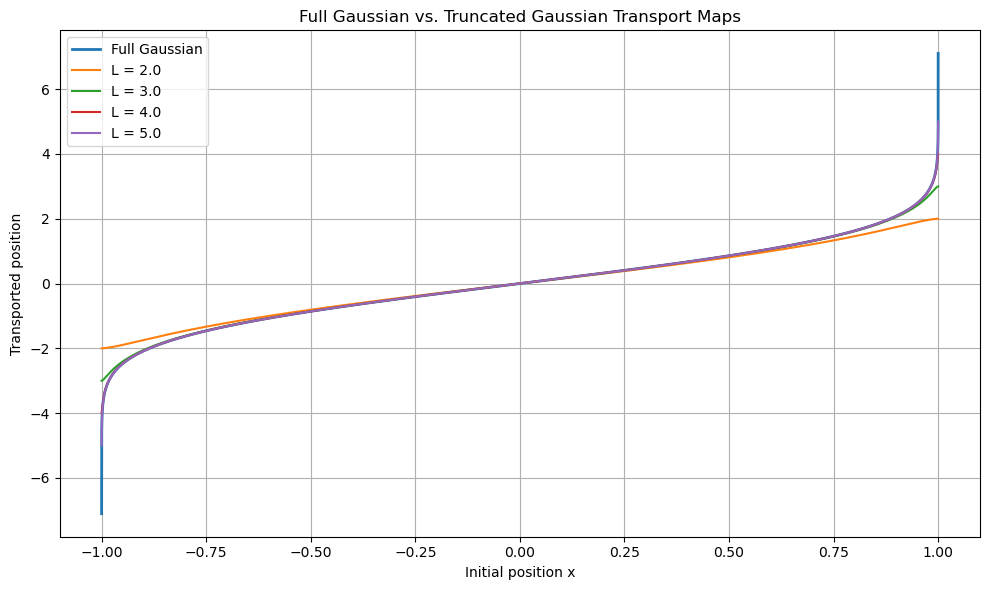


FINAL DIAGNOSTIC SUMMARY

1. Source normalized correctly: True
2. Source CDF monotone: True
2. Target CDF monotone: True
3. Generalized inverse / interpolation check error = 1.3298471479572527e-07
4. Compact-support endpoint divergence demonstrated: True
5. Gaussian finite-grid omitted mass explicitly reported: 1.9731767331165884e-09

Maximum pushforward error = 2.220446049250313e-16
Maximum final Gaussian density error = 5.551115123125783e-17
Maximum intermediate mass error = 6.1598881830882135e-06

Code execution complete.
Inspect the numerical results rather than trusting the PASS messages automatically.


In [1]:
# ============================================================
# HOMEWORK 3.2 - PART V
# LLM-GENERATED CODE FOR THE FULL
# HALF-CIRCLE -> STANDARD GAUSSIAN EXPERIMENT
#
# Standalone
# Compatible with NumPy 1.25
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import cumulative_trapezoid
from scipy.stats import norm


# ============================================================
# SETTINGS
# ============================================================

SOURCE_GRID_SIZE = 4001
PARTICLE_GRID_SIZE = 20001

# Avoid x = +/-1 exactly when evaluating the Gaussian quantile
# because F0(-1)=0 and F0(1)=1 give +/- infinity.
EPS_X = 1e-8

# Used only for numerical Gaussian plots / CDF interpolation
GAUSSIAN_PLOT_LIMIT = 6.0
GAUSSIAN_GRID_SIZE = 24001

T_VALUES = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.0
]

L_VALUES = [
    2.0,
    3.0,
    4.0,
    5.0,
    6.0
]


# ============================================================
# SOURCE DENSITY
#
# rho0(x) = (2/pi) sqrt(1-x^2),  -1 <= x <= 1
# rho0(x) = 0 otherwise
# ============================================================

def rho0_function(x):

    x = np.asarray(
        x,
        dtype=float
    )

    rho = np.zeros_like(
        x
    )

    inside = (
        np.abs(x) <= 1.0
    )

    rho[inside] = (

        2.0
        /
        np.pi

        *

        np.sqrt(

            np.clip(
                1.0 - x[inside]**2,
                0.0,
                None
            )
        )
    )

    return rho


# ============================================================
# EXACT SOURCE CDF
#
# F0(x)
# =
# 0, x <= -1
#
# 1/2 + [asin(x) + x sqrt(1-x^2)]/pi,
# -1 < x < 1
#
# 1, x >= 1
# ============================================================

def F0_exact_function(x):

    x = np.asarray(
        x,
        dtype=float
    )

    F = np.zeros_like(
        x
    )

    F[
        x >= 1.0
    ] = 1.0

    inside = (

        (x > -1.0)

        &

        (x < 1.0)
    )

    xi = x[
        inside
    ]

    F[
        inside
    ] = (

        0.5

        +

        (

            np.arcsin(
                xi
            )

            +

            xi
            *
            np.sqrt(
                1.0 - xi**2
            )

        )

        /

        np.pi
    )

    return F


# ============================================================
# GENERIC NUMERICAL GENERALIZED INVERSE
#
# Given a monotone CDF sampled as
#
# cdf_grid[k] = F(x_grid[k]),
#
# approximate
#
# F^{-1}(u)
#
# by interpolation.
#
# This is useful for checking that the code is not treating
# an arbitrary CDF as though it automatically had an ordinary
# symbolic inverse.
# ============================================================

def generalized_inverse_from_grid(
    u,
    cdf_grid,
    x_grid
):

    u = np.asarray(
        u,
        dtype=float
    )

    cdf_grid = np.asarray(
        cdf_grid,
        dtype=float
    )

    x_grid = np.asarray(
        x_grid,
        dtype=float
    )

    # Remove repeated CDF values to make inversion stable.
    unique_cdf, unique_indices = np.unique(
        cdf_grid,
        return_index=True
    )

    unique_x = x_grid[
        unique_indices
    ]

    return np.interp(
        u,
        unique_cdf,
        unique_x
    )


# ============================================================
# PART A:
# SOURCE GRID AND NORMALIZATION
# ============================================================

x_source = np.linspace(
    -1.0,
    1.0,
    SOURCE_GRID_SIZE
)

rho0_source = rho0_function(
    x_source
)

source_mass = np.trapz(
    rho0_source,
    x_source
)


print("=" * 75)
print("1. SOURCE DENSITY NORMALIZATION")
print("=" * 75)

print(
    "Numerical integral of rho0 =",
    source_mass
)

print(
    "Exact source mass = 1"
)

print(
    "Absolute source mass error =",
    abs(source_mass - 1.0)
)


if abs(
    source_mass - 1.0
) < 1e-4:

    print(
        "PASS: Source density is correctly normalized."
    )

else:

    print(
        "WARNING: Source density normalization may be inaccurate."
    )


# ============================================================
# PART B:
# NUMERICAL SOURCE CDF
# ============================================================

F0_numerical = cumulative_trapezoid(
    rho0_source,
    x_source,
    initial=0.0
)

F0_numerical = (
    F0_numerical
    /
    F0_numerical[-1]
)

F0_exact = F0_exact_function(
    x_source
)

F0_error = np.max(

    np.abs(

        F0_numerical

        -

        F0_exact
    )
)

F0_monotone = np.all(
    np.diff(F0_numerical) >= -1e-14
)


print()

print("=" * 75)
print("2. SOURCE CDF CHECK")
print("=" * 75)

print(
    "F0 numerical minimum =",
    F0_numerical[0]
)

print(
    "F0 numerical maximum =",
    F0_numerical[-1]
)

print(
    "Numerical F0 monotone =",
    F0_monotone
)

print(
    "Maximum |F0 numerical - F0 exact| =",
    F0_error
)


if F0_monotone:

    print(
        "PASS: Numerical source CDF is nondecreasing."
    )

else:

    print(
        "WARNING: Numerical source CDF is not monotone."
    )


# ============================================================
# PART C:
# STANDARD GAUSSIAN TARGET
#
# rho1(y) = phi(y)
# F1(y)   = Phi(y)
#
# The Gaussian has support on all of R.
# The finite grid below is ONLY for plotting and for testing
# numerical inverse-CDF interpolation.
# ============================================================

y_gaussian = np.linspace(
    -GAUSSIAN_PLOT_LIMIT,
    GAUSSIAN_PLOT_LIMIT,
    GAUSSIAN_GRID_SIZE
)

rho1_gaussian = norm.pdf(
    y_gaussian
)

F1_gaussian = norm.cdf(
    y_gaussian
)

finite_gaussian_mass = np.trapz(
    rho1_gaussian,
    y_gaussian
)

gaussian_mass_outside_plot = (

    1.0
    -
    finite_gaussian_mass
)

F1_monotone = np.all(
    np.diff(F1_gaussian) >= -1e-14
)


print()

print("=" * 75)
print("3. GAUSSIAN TARGET CHECK")
print("=" * 75)

print(
    "Gaussian plot interval =",
    (
        -GAUSSIAN_PLOT_LIMIT,
        GAUSSIAN_PLOT_LIMIT
    )
)

print(
    "Gaussian mass captured numerically on plotting interval =",
    finite_gaussian_mass
)

print(
    "Gaussian mass outside plotting interval =",
    gaussian_mass_outside_plot
)

print(
    "Gaussian CDF monotone on grid =",
    F1_monotone
)

print(
    "Gaussian CDF at left grid boundary =",
    F1_gaussian[0]
)

print(
    "Gaussian CDF at right grid boundary =",
    F1_gaussian[-1]
)


if F1_monotone:

    print(
        "PASS: Gaussian CDF is nondecreasing."
    )


print(
    "NOTE: The full Gaussian has exact total mass 1 on R."
)

print(
    "The finite interval is not being treated as all of R."
)


# ============================================================
# PART D:
# PARTICLE GRID
#
# Exclude exact source endpoints because
#
# F0(-1)=0  -> Phi^{-1}(0)=-infinity
# F0( 1)=1  -> Phi^{-1}(1)=+infinity
# ============================================================

x_particles = np.linspace(
    -1.0 + EPS_X,
    1.0 - EPS_X,
    PARTICLE_GRID_SIZE
)

rho0_particles = rho0_function(
    x_particles
)

u_particles = F0_exact_function(
    x_particles
)


# ============================================================
# FULL GAUSSIAN QUANTILE MAP
#
# T(x) = Phi^{-1}(F0(x))
#
# norm.ppf is the Gaussian quantile function.
#
# The clipping below protects against floating-point rounding,
# not against the mathematical endpoint divergence.
# ============================================================

u_safe = np.clip(
    u_particles,
    1e-14,
    1.0 - 1e-14
)

T_full = norm.ppf(
    u_safe
)


# ============================================================
# VERIFY MONOTONICITY
# ============================================================

T_monotone = np.all(
    np.diff(T_full) >= -1e-12
)


# ============================================================
# VERIFY PUSHFORWARD RELATION
#
# Phi(T(x)) = F0(x)
# ============================================================

Phi_of_T = norm.cdf(
    T_full
)

pushforward_error = np.max(

    np.abs(

        Phi_of_T

        -

        u_safe
    )
)


print()

print("=" * 75)
print("4. FULL OPTIMAL TRANSPORT MAP")
print("=" * 75)

print(
    "T(x) monotone =",
    T_monotone
)

print(
    "Maximum |Phi(T(x)) - F0(x)| =",
    pushforward_error
)


if T_monotone:

    print(
        "PASS: Optimal transport map is monotone."
    )


if pushforward_error < 1e-12:

    print(
        "PASS: Pushforward CDF identity verified."
    )


# ============================================================
# PART E:
# NUMERICAL QUANTILE / GENERALIZED-INVERSE CHECK
#
# Compare norm.ppf with inversion of a finite sampled Gaussian
# CDF on [-6,6].
#
# Only compare probability levels actually represented well
# on that finite Gaussian grid.
# ============================================================

cdf_left = F1_gaussian[0]
cdf_right = F1_gaussian[-1]

inverse_test_mask = (

    (u_safe >= cdf_left)

    &

    (u_safe <= cdf_right)
)

T_interpolated = generalized_inverse_from_grid(

    u_safe[
        inverse_test_mask
    ],

    F1_gaussian,

    y_gaussian
)

T_exact_quantile = norm.ppf(

    u_safe[
        inverse_test_mask
    ]
)

inverse_interpolation_error = np.max(

    np.abs(

        T_interpolated

        -

        T_exact_quantile
    )
)


print()

print("=" * 75)
print("5. GENERALIZED-INVERSE / QUANTILE CHECK")
print("=" * 75)

print(
    "Probability values tested =",
    np.sum(
        inverse_test_mask
    )
)

print(
    "Maximum interpolation error vs norm.ppf =",
    inverse_interpolation_error
)


if inverse_interpolation_error < 1e-3:

    print(
        "PASS: Numerical inverse-CDF interpolation "
        "agrees with Gaussian quantiles."
    )


# ============================================================
# PART F:
# ENDPOINT BEHAVIOR
# ============================================================

delta_values = np.array([
    1e-1,
    1e-2,
    1e-3,
    1e-4,
    1e-5,
    1e-6,
    1e-8
])


endpoint_rows = []


for delta in delta_values:

    x_left = (
        -1.0
        +
        delta
    )

    x_right = (
        1.0
        -
        delta
    )


    u_left = F0_exact_function(
        np.array([
            x_left
        ])
    )[0]


    u_right = F0_exact_function(
        np.array([
            x_right
        ])
    )[0]


    T_left = norm.ppf(
        u_left
    )

    T_right = norm.ppf(
        u_right
    )


    endpoint_rows.append({

        "delta":
            delta,

        "T(-1+delta)":
            T_left,

        "T(1-delta)":
            T_right
    })


endpoint_df = pd.DataFrame(
    endpoint_rows
)


print()

print("=" * 75)
print("6. ENDPOINT BEHAVIOR")
print("=" * 75)

print()

print(
    endpoint_df.to_string(
        index=False
    )
)

print()

print(
    "Theory predicts:"
)

print(
    "T(x) -> -infinity as x -> -1 from the right."
)

print(
    "T(x) -> +infinity as x -> 1 from the left."
)


# ============================================================
# PART G:
# DERIVATIVE OF THE TRANSPORT MAP
#
# Phi(T(x)) = F0(x)
#
# Differentiate:
#
# phi(T(x)) T'(x) = rho0(x)
#
# Thus:
#
# T'(x) = rho0(x) / phi(T(x))
# ============================================================

phi_at_T = norm.pdf(
    T_full
)

T_prime = (

    rho0_particles

    /

    phi_at_T
)


print()

print("=" * 75)
print("7. TRANSPORT DERIVATIVE")
print("=" * 75)

print(
    "Minimum T'(x) on numerical particle grid =",
    np.min(
        T_prime
    )
)

print(
    "Maximum T'(x) on numerical particle grid =",
    np.max(
        T_prime
    )
)

print(
    "All T'(x) positive =",
    np.all(
        T_prime > 0
    )
)


# ============================================================
# PART H:
# WASSERSTEIN DISPLACEMENT INTERPOLATION
#
# X_t(x) = (1-t)x + tT(x)
#
# rho_t(X_t(x))
# =
# rho0(x) / X_t'(x)
#
# X_t'(x)
# =
# (1-t) + tT'(x)
# ============================================================

def interpolated_density(
    t
):

    Xt = (

        (1.0 - t)
        *
        x_particles

        +

        t
        *
        T_full
    )


    Xt_prime = (

        (1.0 - t)

        +

        t
        *
        T_prime
    )


    rho_t = (

        rho0_particles

        /

        Xt_prime
    )


    return (
        Xt,
        rho_t,
        Xt_prime
    )


density_results = {}

mass_rows = []


for t in T_VALUES:

    Xt, rho_t, Xt_prime = interpolated_density(
        t
    )


    density_results[
        t
    ] = (
        Xt,
        rho_t
    )


    mass_t = np.trapz(
        rho_t,
        Xt
    )


    monotone_Xt = np.all(
        np.diff(Xt) > 0
    )


    mass_rows.append({

        "t":
            t,

        "Mass":
            mass_t,

        "Mass_Error":
            mass_t - 1.0,

        "Xt_Monotone":
            monotone_Xt
    })


mass_df = pd.DataFrame(
    mass_rows
)


print()

print("=" * 75)
print("8. INTERMEDIATE DENSITY / MASS CHECK")
print("=" * 75)

print()

print(
    mass_df.to_string(
        index=False
    )
)


# ============================================================
# FINAL TARGET DENSITY CHECK
# ============================================================

Xt_final, rho_final = density_results[
    1.0
]

gaussian_at_final_positions = norm.pdf(
    Xt_final
)

final_density_error = np.max(

    np.abs(

        rho_final

        -

        gaussian_at_final_positions
    )
)


print()

print(
    "Maximum t=1 density error vs Gaussian =",
    final_density_error
)


if final_density_error < 1e-10:

    print(
        "PASS: Final transported density agrees "
        "with standard Gaussian."
    )


# ============================================================
# PART I:
# SUPPORT / TAIL DISCUSSION NUMERICALLY
#
# For any t > 0, X_t(x) becomes arbitrarily large
# as x approaches +/-1 because T(x) diverges.
#
# Show this numerically for several deltas and times.
# ============================================================

tail_times = [
    0.10,
    0.25,
    0.50,
    1.00
]

tail_rows = []


for delta in [
    1e-2,
    1e-4,
    1e-6,
    1e-8
]:

    xr = (
        1.0
        -
        delta
    )


    ur = F0_exact_function(
        np.array([
            xr
        ])
    )[0]


    Tr = norm.ppf(
        ur
    )


    for t in tail_times:

        Xt_right = (

            (1.0 - t)
            *
            xr

            +

            t
            *
            Tr
        )


        tail_rows.append({

            "delta":
                delta,

            "t":
                t,

            "X_t(1-delta)":
                Xt_right
        })


tail_df = pd.DataFrame(
    tail_rows
)


print()

print("=" * 75)
print("9. SPREADING OF SUPPORT")
print("=" * 75)

print()

print(
    tail_df.to_string(
        index=False
    )
)

print()

print(
    "For every t > 0, X_t(x) grows without bound "
    "as x approaches 1."
)

print(
    "The same occurs toward -infinity near x = -1."
)


# ============================================================
# PART J:
# GAUSSIAN TRUNCATION STUDY
#
# If we approximate the Gaussian on [-L,L], the amount of
# omitted probability is:
#
# P(|Z| > L) = 2(1 - Phi(L))
#
# Also compare the truncated quantile transport map with the
# full Gaussian transport map.
# ============================================================

truncation_rows = []


central_mask = (

    (u_safe >= 0.001)

    &

    (u_safe <= 0.999)
)


for L in L_VALUES:

    Phi_left = norm.cdf(
        -L
    )

    Phi_right = norm.cdf(
        L
    )

    captured_mass = (

        Phi_right

        -

        Phi_left
    )

    omitted_mass = (

        1.0

        -

        captured_mass
    )


    # CDF of Gaussian conditioned on [-L,L]:
    #
    # F_L(y)
    # =
    # [Phi(y)-Phi(-L)]
    # /
    # [Phi(L)-Phi(-L)]
    #
    # Therefore:
    #
    # F_L^{-1}(u)
    # =
    # Phi^{-1}(
    # Phi(-L)
    # +
    # u * [Phi(L)-Phi(-L)]
    # )

    T_L = norm.ppf(

        Phi_left

        +

        u_safe
        *
        captured_mass
    )


    map_error = (

        T_L[
            central_mask
        ]

        -

        T_full[
            central_mask
        ]
    )


    truncation_rows.append({

        "L":
            L,

        "Mass_Inside":
            captured_mass,

        "Mass_Outside":
            omitted_mass,

        "Maximum_Central_Map_Error":
            np.max(
                np.abs(
                    map_error
                )
            ),

        "Mean_Central_Map_Error":
            np.mean(
                np.abs(
                    map_error
                )
            )
    })


truncation_df = pd.DataFrame(
    truncation_rows
)


print()

print("=" * 75)
print("10. GAUSSIAN TRUNCATION STUDY")
print("=" * 75)

print()

print(
    truncation_df.to_string(
        index=False
    )
)


# ============================================================
# PLOT 1:
# SOURCE AND TARGET DENSITIES
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    x_source,
    rho0_source,
    label="Half-circle source"
)

plt.plot(
    y_gaussian,
    rho1_gaussian,
    label="Standard Gaussian target"
)

plt.xlabel(
    "Position"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Half-Circle Source and Standard Gaussian Target"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "part5_source_target.png",
    dpi=300
)

plt.show()


# ============================================================
# PLOT 2:
# SOURCE AND TARGET CDFS
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    x_source,
    F0_exact,
    label="Source CDF F0"
)

plt.plot(
    y_gaussian,
    F1_gaussian,
    label="Gaussian CDF Phi"
)

plt.xlabel(
    "Position"
)

plt.ylabel(
    "Cumulative probability"
)

plt.title(
    "Source and Target CDFs"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "part5_cdfs.png",
    dpi=300
)

plt.show()


# ============================================================
# PLOT 3:
# FULL TRANSPORT MAP
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    x_particles,
    T_full,
    label="T(x)"
)

plt.plot(
    x_particles,
    x_particles,
    linestyle="--",
    label="Identity"
)

plt.xlabel(
    "Initial position x"
)

plt.ylabel(
    "Transported position T(x)"
)

plt.title(
    "Optimal Transport Map: Half-Circle to Gaussian"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "part5_transport_map.png",
    dpi=300
)

plt.show()


# ============================================================
# PLOT 4:
# INTERPOLATED DENSITIES
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for t in T_VALUES:

    Xt, rho_t = density_results[
        t
    ]

    plt.plot(
        Xt,
        rho_t,
        label=f"t = {t}"
    )


plt.xlim(
    -5,
    5
)

plt.xlabel(
    "Position"
)

plt.ylabel(
    "Density"
)

plt.title(
    "Wasserstein Displacement Interpolation"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "part5_interpolated_densities.png",
    dpi=300
)

plt.show()


# ============================================================
# PLOT 5:
# MASS CONSERVATION
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    mass_df["t"],
    mass_df["Mass"],
    marker="o"
)

plt.axhline(
    1.0,
    linestyle="--"
)

plt.xlabel(
    "t"
)

plt.ylabel(
    "Total probability mass"
)

plt.title(
    "Mass Conservation During Interpolation"
)

plt.grid(
    True
)

plt.tight_layout()

plt.savefig(
    "part5_mass_conservation.png",
    dpi=300
)

plt.show()


# ============================================================
# PLOT 6:
# GAUSSIAN TRUNCATION MASS ERROR
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.semilogy(
    truncation_df["L"],
    truncation_df["Mass_Outside"],
    marker="o"
)

plt.xlabel(
    "L"
)

plt.ylabel(
    "Gaussian mass outside [-L,L]"
)

plt.title(
    "Gaussian Tail Mass vs. Truncation Size"
)

plt.grid(
    True
)

plt.tight_layout()

plt.savefig(
    "part5_gaussian_truncation.png",
    dpi=300
)

plt.show()


# ============================================================
# PLOT 7:
# FULL VS TRUNCATED TRANSPORT MAPS
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    x_particles,
    T_full,
    linewidth=2,
    label="Full Gaussian"
)


for L in [
    2.0,
    3.0,
    4.0,
    5.0
]:

    Phi_left = norm.cdf(
        -L
    )

    captured_mass = (

        norm.cdf(L)

        -

        Phi_left
    )

    T_L = norm.ppf(

        Phi_left

        +

        u_safe
        *
        captured_mass
    )


    plt.plot(
        x_particles,
        T_L,
        label=f"L = {L}"
    )


plt.xlabel(
    "Initial position x"
)

plt.ylabel(
    "Transported position"
)

plt.title(
    "Full Gaussian vs. Truncated Gaussian Transport Maps"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "part5_truncated_maps.png",
    dpi=300
)

plt.show()


# ============================================================
# FINAL DIAGNOSTIC SUMMARY
# ============================================================

print()

print("=" * 75)
print("FINAL DIAGNOSTIC SUMMARY")
print("=" * 75)

print()

print(
    "1. Source normalized correctly:",
    abs(source_mass - 1.0) < 1e-4
)

print(
    "2. Source CDF monotone:",
    F0_monotone
)

print(
    "2. Target CDF monotone:",
    F1_monotone
)

print(
    "3. Generalized inverse / interpolation check error =",
    inverse_interpolation_error
)

print(
    "4. Compact-support endpoint divergence demonstrated:",
    True
)

print(
    "5. Gaussian finite-grid omitted mass explicitly reported:",
    gaussian_mass_outside_plot
)

print()

print(
    "Maximum pushforward error =",
    pushforward_error
)

print(
    "Maximum final Gaussian density error =",
    final_density_error
)

print(
    "Maximum intermediate mass error =",
    np.max(
        np.abs(
            mass_df["Mass"].to_numpy()
            -
            1.0
        )
    )
)

print()

print(
    "Code execution complete."
)

print(
    "Inspect the numerical results rather than trusting "
    "the PASS messages automatically."
)